# <font color='#2E86C1' size=6>**Feature engineering and selection**</font>

**Workflow:** [01 Data cleaning](01_data_cleaning.ipynb) → [02 Customer table](02_customer_table.ipynb) → [03 Missing values](03_missing_values.ipynb) → [04 Outliers](04_outlier_detection.ipynb) → [05 Preprocessing recipe and models](05_preprocessing_and_models.ipynb) → **06 Feature engineering and selection**

**Scope of this notebook.** Section 1 decides which groups of new columns each task adds (purchase-time features, the customer table, rare-category grouping). Sections 2–7 (diagnosis) then answer three questions on the **development set** (the locked test set is never touched); sections 8 and 9 then test, by paired ablation on the same temporal folds, the engineered features (step 2) and the feature-selection step (step 3):

1. **Redundancy** (section 3): which features carry the same information (Spearman clusters, VIF)?
2. **Relevance** (section 4): which features carry information about the target (mutual information)?
3. **Usefulness for the chosen model** (section 5): what happens to the temporal-CV score when a feature is shuffled (out-of-fold permutation importance)?

Section 6 merges the three into one table of **drop candidates**. They are candidates, not decisions: each one is confirmed or rejected afterwards by a paired ablation on the same temporal folds (`compare_preprocessing_variants` + `paired_comparison`), as in section 1.2.

**Reading rules**
- Mutual information and correlations are *descriptive*: they use all development rows at once, so they must not be used to pick features without the ablation.
- Permutation importance is computed **out of fold**: the model is fitted on the training rows of each temporal fold and the column is shuffled in the validation rows of that fold only.
- Features that are not in the current recipe (`margin`, `discount_rate`, ...) are included in sections 3 and 4 so they can be compared with the ones in use; section 5 only covers the features the recipe actually feeds to the model.

## Table of Contents <a class="anchor" id="toc"></a>
- [0. Setup](#setup)
- [1. Data additions: new features, customer table, rare categories](#additions)
- [2. Data and per-task feature groups](#data)
- [3. Redundancy](#redundancy)
- [4. Relevance: mutual information with the target](#relevance)
- [5. Usefulness for the chosen model: out-of-fold permutation importance](#importance)
- [6. Drop candidates](#candidates)
- [7. What to do with this](#what-to-do)
- [8. Step 2: engineered features, paired ablation](#engineering)
- [9. Step 3: feature selection, paired ablation](#selection)
- [10. Decisions](#decisions)
- [11. From this notebook to the pipeline](#to-pipeline)

# <font color='#2E86C1' size=6>**0. Setup**</font> <a class="anchor" id="setup"></a>

[Back to TOC](#toc)

In [1]:
import os
import re
import sys
import warnings
from pathlib import Path

# run from the project root, whether Jupyter was started there or in notebooks/
ROOT = Path.cwd() if (Path.cwd() / "config.yaml").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
from sklearn.feature_selection import mutual_info_classif, mutual_info_regression
from sklearn.inspection import permutation_importance

from src.evaluate import (
    compare_preprocessing_variants, greater_is_better, paired_comparison, select_scoring, temporal_folds,
)
from src.pipeline import build_pipeline, prepare_task_data
from src.preprocessing import task_preprocessing_config
from src.tasks import TASKS, get_task

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

with open("config.yaml", encoding="utf-8") as f:
    config = yaml.safe_load(f)
data_cfg = config["data"]

SCORING = {task: select_scoring(TASKS[task].evaluate.SCORING, config[task]["metrics"]) for task in TASKS}
SEED = config["preprocessing"].get("random_state", 42)

In [2]:
# section 1: each task's development set and temporal folds (notebook 01, sections 6-7) and model
diag_cfg, prep_cfg = config["diagnostics"], config["preprocessing"]
TASK_MODELS = {task: get_task(task).model for task in TASKS}
splits, task_folds = {}, {}
for task in TASKS:
    d = prepare_task_data(config, task)
    splits[task] = (d["X_dev"], d["X_test"], d["y_dev"], d["y_test"], d["extras_dev"], d["extras_test"])
    task_folds[task] = temporal_folds(d["extras_dev"][data_cfg["date_column"]], config["cv"]["n_splits"], config["cv"]["gap_days"])


# <font color='#2E86C1' size=6>**1. Data additions: new features, customer table, rare categories**</font> <a class="anchor" id="additions"></a>

Each addition is measured the same way: the task's chosen recipe and model are scored **with and without** the addition, on the same temporal folds, and compared fold by fold. An addition is kept when it helps; when it doesn't, the simpler pipeline wins. The consistency rules are tested the same way in notebook 01 (section 8), and the customer table is prepared and joined in notebook 02.

[Back to TOC](#toc)

### 1.1 Purchase-time features

Only information known **at the moment of the purchase** is used (`config.yaml` → `diagnostics.date_features`, `derived_features`):
- **date parts:** `purchase_month`, `purchase_weekday`;
- **ratios of the same row:** `margin` (net − cost), `margin_rate`, `discount_rate` (discounts / gross), `avg_line_value` (net / lines), `spend_share_30d` and `spend_share_90d` (recent spend / 365-day spend).

No feature looks at later purchases or at other rows.

### 1.2 Which additions help? Ablation per task

`original`: the 26 + 6 features of the shared recipe (`config.yaml` → `preprocessing`). `all new`: plus every date, ratio and customer feature. Then each group is removed in turn (`original + date + customer` is `all new` without the ratios). Rare-category grouping (`rare_category_min_count`) is tested on top: categories with fewer than N **training** rows (`transport_method` has 80 levels, 40 of them under 10 rows) become `rare`. The threshold is learned inside each fold by `RareCategoryGrouper`.

In [3]:
DATE_FEATURES = [f"purchase_{part}" for part in diag_cfg["date_features"]]
# the purchase-time ratios of section 1.1 (diagnostics.derived_features also holds the engineered
# features of section 8, which are tested there)
DERIVED_FEATURES = ["margin", "margin_rate", "discount_rate", "avg_line_value", "spend_share_30d", "spend_share_90d"]
CUSTOMER_NUMERIC = list(config["customers"]["derived_features"])
# the customer-table geography as added in this section (notebook 02 adds and tests two more customer features)
CUSTOMER_CATEGORICAL = ["country_or_region", "commercial_region", "island", "municipality"]

ablation_tables, ablation_paired = {}, {}
for task in ["classification", "regression"]:
    X_dev, _, y_dev, _, _, _ = splits[task]
    recipe = task_preprocessing_config(config, task)
    original = {**recipe, "numeric_features": prep_cfg["numeric_features"], "categorical_features": prep_cfg["categorical_features"]}

    def with_features(numeric=(), categorical=(), **extra):
        return {**original, "numeric_features": original["numeric_features"] + list(numeric),
                "categorical_features": original["categorical_features"] + list(categorical), **extra}

    all_numeric, all_categorical = DATE_FEATURES + DERIVED_FEATURES + CUSTOMER_NUMERIC, CUSTOMER_CATEGORICAL
    variants = {
        "original": original,
        "all new": with_features(all_numeric, all_categorical),
        "all new - date": with_features(DERIVED_FEATURES + CUSTOMER_NUMERIC, all_categorical),
        "all new - customer": with_features(DATE_FEATURES + DERIVED_FEATURES),
        "original + date + customer": with_features(DATE_FEATURES + CUSTOMER_NUMERIC, CUSTOMER_CATEGORICAL),
        "original + rare >= 10": with_features(rare_category_min_count=10),
        "original + rare >= 30": with_features(rare_category_min_count=30),
    }
    metric = config[task]["selection_metric"]
    table, per_fold = compare_preprocessing_variants(
        variants, lambda: TASK_MODELS[task].build_model(config[task]["model"]), X_dev, y_dev, task_folds[task], SCORING[task], metric)
    ablation_tables[task] = table
    ablation_paired[task] = pd.DataFrame([
        {"A": a, "B": b, **paired_comparison(per_fold[a], per_fold[b], metric != "rmse")}
        for a, b in [("all new", "original"), ("all new", "all new - date"), ("all new", "original + date + customer"),
                     ("all new", "all new - customer"), ("original + date + customer", "original"),
                     ("original + rare >= 10", "original")]
    ])
    print(f"\n{task}: validation {metric}")
    display(table.round(4))
    display(ablation_paired[task].round(4))


classification: validation accuracy


,variant,mean_accuracy,std_accuracy
0,all new - customer,0.7088,0.0137
1,original,0.7078,0.0155
2,all new - date,0.7050,0.0114
3,all new,0.7045,0.0102
4,original + rare >= 30,0.7031,0.0166
5,original + date + customer,0.7023,0.0164
6,original + rare >= 10,0.7004,0.0158


,A,B,mean_advantage,se,folds_a_better,n_folds,decisive
0,all new,original,-0.0033,0.0037,1,5,False
1,all new,all new - date,-0.0005,0.0024,2,5,False
2,all new,original + date + customer,0.0022,0.0033,2,5,False
3,all new,all new - customer,-0.0043,0.0018,0,5,True
4,original + date + customer,original,-0.0055,0.0015,0,5,True
5,original + rare >= 10,original,-0.0074,0.0029,0,5,True



regression: validation rmse


,variant,mean_rmse,std_rmse
0,all new,1939.8483,181.4177
1,original + date + customer,1943.1552,164.5057
2,all new - customer,1983.8296,216.8361
3,all new - date,1987.8906,203.5800
4,original,1994.9212,203.9603
5,original + rare >= 30,1998.8072,207.0372
6,original + rare >= 10,2001.4086,210.8245


,A,B,mean_advantage,se,folds_a_better,n_folds,decisive
0,all new,original,55.0728,45.4760,4,5,False
1,all new,all new - date,48.0423,31.5686,5,5,False
2,all new,original + date + customer,3.3068,12.6043,3,5,False
3,all new,all new - customer,43.9812,33.0332,3,5,False
4,original + date + customer,original,51.7660,37.6706,4,5,False
5,original + rare >= 10,original,-6.4874,3.6305,1,5,False


**Verdict** (stored per task in `config.yaml` → `<task>.preprocessing`):

| Addition | Classification (accuracy) | Regression (RMSE) | Decision |
|---|---|---|---|
| all new features vs original | −0.003 (better on 1/5 folds) | 55 RMSE better (4/5) | per task |
| date parts (`purchase_month`, `purchase_weekday`) | −0.0005 (noise) | **48 RMSE better with them, 5/5 folds** | regression: **kept** |
| customer table | **0.004 better *without*, decisive** | **44 RMSE better with them** | regression: **kept** |
| ratios (margin, discount rate, …) | +0.002 (noise) | 3 RMSE (noise) | not used: no gain, more columns |
| rare-category grouping (≥ 10 / ≥ 30 rows) | −0.007 (decisive) / −0.005 | 6 RMSE worse / 4 RMSE worse (noise) | **off** for both (`rare_category_min_count: 0`) |

- **Classification keeps the original 32 features.** None of the additions helps logistic regression; the customer table, and date + customer together, decisively hurt it.
- **Regression adds the date parts and the customer table** (`extra_numeric_features`, `extra_categorical_features`). Together they lower RMSE by 52, better on 4 of 5 folds, and the date parts help on every fold. Spend seems to depend on season and on where the customer is, while repurchase doesn't. Each gain on its own is under 2 SE, but both have a clear reason and point the same way.
- **Rare categories are not grouped.** The target encoder already shrinks a rare category's mean towards the overall mean, so grouping only throws away information.

The ratio features stay computed in `config.yaml` (`derived_features`) and are one config line away from either task.

# <font color='#2E86C1' size=6>**2. Data and per-task feature groups**</font> <a class="anchor" id="data"></a>

`prepare_task_data` runs the same load, validate, clean and split steps as `main.py`, so `X_dev` already holds **every** column the cleaning step produces (including the ones the recipe does not use). Each task keeps its own development set: the regression one only has repeat purchasers.

[Back to TOC](#toc)

In [4]:
data, folds = {}, {}
for task in TASKS:
    data[task] = prepare_task_data(config, task)
    dates = data[task]["extras_dev"][data_cfg["date_column"]]
    folds[task] = temporal_folds(dates, config["cv"]["n_splits"], config["cv"]["gap_days"])


def feature_groups(task):
    """Which columns of X_dev are categorical, numeric-like, and which ones the recipe uses."""
    recipe, X = data[task]["preprocessing_config"], data[task]["X_dev"]
    categorical = [c for c in X.columns if str(X[c].dtype) == "category"]
    numeric = [c for c in X.columns if c not in categorical]
    used = (recipe["numeric_features"] + recipe["categorical_features"]
            + list(recipe.get("flag_features", [])))
    return {"categorical": categorical, "numeric": numeric, "used": used, "recipe": recipe}


groups = {task: feature_groups(task) for task in TASKS}
summary = pd.DataFrame({
    task: {"dev rows": len(data[task]["X_dev"]), "temporal folds": len(folds[task]),
           "columns in X_dev": data[task]["X_dev"].shape[1], "columns used by the recipe": len(groups[task]["used"]),
           "numeric-like not used": len([c for c in groups[task]["numeric"] if c not in groups[task]["used"]]),
           "categorical not used": len([c for c in groups[task]["categorical"] if c not in groups[task]["used"]])}
    for task in TASKS})
display(summary)

,classification,regression
dev rows,5024,2659
temporal folds,5,5
columns in X_dev,56,56
columns used by the recipe,34,43
numeric-like not used,18,13
categorical not used,4,0


# <font color='#2E86C1' size=6>**3. Redundancy**</font> <a class="anchor" id="redundancy"></a>

### 3.1 Spearman correlation clusters

Spearman (rank) correlation, because most money and count columns are heavily skewed. Features are grouped by average-linkage hierarchical clustering on `1 - |rho|`, cutting at `|rho| >= 0.90` on average. A cluster with more than one member is a group of near-duplicates: at most one (or a ratio of them) should be needed by a linear model.

[Back to TOC](#toc)

In [5]:
RHO_CUT = 0.90


def numeric_frame(task):
    X, g = data[task]["X_dev"], groups[task]
    return X[g["numeric"]].astype("float64")


def correlation_clusters(task):
    Xn = numeric_frame(task)
    Xn = Xn.loc[:, Xn.nunique() > 1]                         # constants have no correlation
    rho = Xn.corr(method="spearman").fillna(0.0)
    dist = 1 - rho.abs().to_numpy()
    np.fill_diagonal(dist, 0.0)
    labels = hierarchy.fcluster(hierarchy.linkage(squareform(dist, checks=False), "average"),
                                t=1 - RHO_CUT, criterion="distance")
    return rho, pd.Series(labels, index=rho.index, name="cluster")


rho, cluster = {}, {}
for task in TASKS:
    rho[task], cluster[task] = correlation_clusters(task)
    sizes = cluster[task].map(cluster[task].value_counts())
    rows = []
    for label in sorted(cluster[task][sizes > 1].unique()):
        members = cluster[task][cluster[task] == label].index.tolist()
        sub = rho[task].loc[members, members].abs().to_numpy()
        rows.append({"cluster": label, "size": len(members),
                     "min |rho|": sub[np.triu_indices(len(members), 1)].min().round(3),
                     "in recipe": [m for m in members if m in groups[task]["used"]],
                     "not in recipe": [m for m in members if m not in groups[task]["used"]]})
    print(f"\n{task.upper()}: {len(rows)} clusters with more than one feature (|rho| >= {RHO_CUT})")
    display(pd.DataFrame(rows).set_index("cluster"))


CLASSIFICATION: 8 clusters with more than one feature (|rho| >= 0.9)


,size,min |rho|,in recipe,not in recipe
cluster,,,,
3,2,0.942,[net_total],[margin]
10,2,0.921,"[prior_std_purchase_value, prior_max_purchase_...",[]
12,2,0.907,"[prior_purchase_count, prior_total_spend]",[]
13,2,0.904,"[spend_180d, spend_365d]",[]
25,3,0.945,"[purchase_count_30d, spend_30d]",[spend_share_30d]
26,2,0.956,[],"[spend_share_90d, count_share_90d]"
27,2,0.921,"[purchase_count_90d, spend_90d]",[]
29,2,0.902,[line_discount_total],[discount_rate]



REGRESSION: 5 clusters with more than one feature (|rho| >= 0.9)


,size,min |rho|,in recipe,not in recipe
cluster,,,,
6,2,0.939,[net_total],[margin]
12,2,0.905,[],"[spend_share_90d, count_share_90d]"
15,3,0.893,"[purchase_count_30d, spend_30d]",[spend_share_30d]
19,2,0.916,"[prior_std_purchase_value, prior_max_purchase_...",[]
24,2,0.902,"[spend_180d, spend_365d]",[]


### 3.2 Strongest pairs

The clusters above can chain features together; the pairs below show the actual strength of each link.

In [6]:
def top_pairs(task, n=15):
    r = rho[task].abs()
    upper = r.where(np.triu(np.ones(r.shape, dtype=bool), 1)).stack()
    pairs = upper.sort_values(ascending=False).head(n).rename("|rho|").reset_index()
    pairs.columns = ["feature A", "feature B", "|rho|"]
    pairs["both in recipe"] = [a in groups[task]["used"] and b in groups[task]["used"]
                               for a, b in zip(pairs["feature A"], pairs["feature B"])]
    return pairs.round(3)


for task in TASKS:
    print(f"\n{task.upper()}")
    display(top_pairs(task))


CLASSIFICATION


,feature A,feature B,|rho|,both in recipe
0,purchase_count_30d,spend_30d,0.965,True
1,spend_30d,spend_share_30d,0.965,False
2,spend_share_90d,count_share_90d,0.956,False
3,purchase_count_30d,spend_share_30d,0.945,False
4,net_total,margin,0.942,False
5,prior_std_purchase_value,prior_max_purchase_value,0.921,True
6,purchase_count_90d,spend_90d,0.921,True
7,prior_purchase_count,prior_total_spend,0.907,True
8,spend_180d,spend_365d,0.904,True
9,line_discount_total,discount_rate,0.902,False



REGRESSION


,feature A,feature B,|rho|,both in recipe
0,spend_30d,spend_share_30d,0.947,False
1,net_total,margin,0.939,False
2,net_total,total_tax,0.928,True
3,purchase_count_30d,spend_30d,0.925,True
4,prior_std_purchase_value,prior_max_purchase_value,0.916,True
5,spend_share_90d,count_share_90d,0.905,False
6,spend_180d,spend_365d,0.902,True
7,purchase_count_180d,purchase_count_365d,0.898,True
8,purchase_count_30d,spend_share_30d,0.893,False
9,customer_tenure_days,years_as_customer,0.889,True


### 3.3 Variance inflation factor (features in the recipe)

VIF of feature *j* is `1 / (1 - R²_j)`, with R²_j from regressing it on all the others. It is the number that matters for **logistic regression and Ridge** (classification's current model): a VIF above 10 means the coefficient is poorly determined, even if prediction is fine. Trees and forests are not affected by collinearity in the same way. Median imputation and standardisation first, same as the recipe; the VIF comes from the diagonal of the inverse correlation matrix.

In [7]:
def vif_table(task):
    Xn = numeric_frame(task)
    cols = [c for c in groups[task]["recipe"]["numeric_features"] + list(groups[task]["recipe"].get("flag_features", []))
            if c in Xn.columns]
    Z = Xn[cols]
    Z = Z.fillna(Z.median())
    Z = Z.loc[:, Z.std() > 0]
    Z = (Z - Z.mean()) / Z.std()
    inv = np.linalg.pinv(np.corrcoef(Z.to_numpy(), rowvar=False))
    return pd.Series(np.diag(inv), index=Z.columns, name="VIF").sort_values(ascending=False)


vif = {task: vif_table(task) for task in TASKS}
for task in TASKS:
    print(f"\n{task.upper()}: {int((vif[task] > 10).sum())} of {len(vif[task])} features have VIF > 10, "
          f"{int((vif[task] > 5).sum())} have VIF > 5 (top 12 below)")
    display(vif[task].head(12).round(1).to_frame())


CLASSIFICATION: 7 of 28 features have VIF > 10, 15 have VIF > 5 (top 12 below)


,VIF
purchase_count_180d,29.2
purchase_count_365d,22.5
prior_std_purchase_value,19.8
prior_mean_purchase_value,19.5
purchase_count_90d,16.6
prior_max_purchase_value,12.3
spend_180d,10.7
spend_365d,8.9
prior_purchase_count,8.6
prior_total_spend,8.3



REGRESSION: 7 of 33 features have VIF > 10, 16 have VIF > 5 (top 12 below)


,VIF
purchase_count_180d,29.6
purchase_count_365d,21.8
prior_std_purchase_value,18.5
prior_mean_purchase_value,17.8
purchase_count_90d,16.5
prior_max_purchase_value,10.7
spend_180d,10.2
net_total,8.6
spend_365d,8.5
prior_purchase_count,8.3


# <font color='#2E86C1' size=6>**4. Relevance: mutual information with the target**</font> <a class="anchor" id="relevance"></a>

Mutual information captures non-linear dependence too. Numeric columns (median-imputed) use the k-nearest-neighbour estimator; categorical columns and 0/1 flags are treated as discrete variables (integer codes). Each column is estimated on its own so the numbers do not change when a column is added to the data. Estimates are noisy on small samples (regression has fewer than 3,000 rows), so treat the ranking as a guide, and look at the gap to the `random_noise`-like level rather than at the exact order. To get that reference level, a **shuffled copy of the target** is scored too: any feature whose MI is not clearly above it carries no usable signal.

[Back to TOC](#toc)

In [8]:
def mutual_information(task, seed=SEED):
    """MI of every column with the target, and with a shuffled copy of the target (noise floor).
    One column at a time: the kNN estimator adds random noise, and with all columns in one call
    that noise (hence every estimate) would change whenever a column is added to X_dev.
    Categorical columns and 0/1 flags are discrete variables, the rest continuous."""
    X, y = data[task]["X_dev"], data[task]["y_dev"]
    g = groups[task]
    num = X[g["numeric"]].astype("float64")
    num = num.fillna(num.median())
    cat = X[g["categorical"]].apply(lambda s: s.cat.codes if str(s.dtype) == "category" else s)
    frame = pd.concat([num, cat], axis=1)
    discrete = {c: (c in g["categorical"]) or frame[c].nunique() <= 2 for c in frame.columns}
    mi_function = mutual_info_classif if task == "classification" else mutual_info_regression
    target = y.to_numpy()
    shuffled = np.random.default_rng(seed).permutation(target)
    estimate = lambda c, t: mi_function(frame[[c]], t, discrete_features=[discrete[c]], random_state=seed)[0]
    mi = pd.Series({c: estimate(c, target) for c in frame.columns})
    floor = pd.Series({c: estimate(c, shuffled) for c in frame.columns})
    return mi, floor


mi, mi_floor = {}, {}
for task in TASKS:
    mi[task], mi_floor[task] = mutual_information(task)
    print(f"{task}: MI of the shuffled target, max over features = {mi_floor[task].max():.4f}, "
          f"median = {mi_floor[task].median():.4f}")
for task in TASKS:
    print(f"\n{task.upper()}: top 12 features by mutual information")
    display(pd.DataFrame({"MI": mi[task], "in recipe": [c in groups[task]["used"] for c in mi[task].index]})
            .sort_values("MI", ascending=False).head(12).round(4))

classification: MI of the shuffled target, max over features = 0.0178, median = 0.0009
regression: MI of the shuffled target, max over features = 0.0389, median = 0.0009

CLASSIFICATION: top 12 features by mutual information


,MI,in recipe
prior_max_purchase_value,0.1529,True
prior_min_purchase_value,0.1454,True
purchase_count_365d,0.1208,True
purchase_rate,0.1140,False
prior_mean_gap_days,0.1071,True
purchase_count_180d,0.1030,True
purchase_count_90d,0.1009,True
count_share_90d,0.0960,False
spend_365d,0.0930,True
spend_180d,0.0846,True



REGRESSION: top 12 features by mutual information


,MI,in recipe
spend_365d,0.2980,True
prior_max_purchase_value,0.2959,True
purchase_rate,0.2602,False
prior_purchase_count,0.2466,True
municipality,0.2424,True
spend_180d,0.2379,True
prior_total_spend,0.2333,True
purchase_count_180d,0.2219,True
purchase_count_365d,0.2215,True
prior_std_purchase_value,0.2135,True


# <font color='#2E86C1' size=6>**5. Usefulness for the chosen model: out-of-fold permutation importance**</font> <a class="anchor" id="importance"></a>

For each temporal fold: fit the task's **current** pipeline (recipe + model from `config.yaml`) on the training rows, then shuffle one column at a time in the validation rows and measure how much the selection metric gets worse (5 repeats). The importance is expressed in the metric's own units (accuracy points for classification, RMSE in euros for regression), so a positive number means "the model needs this column". Shuffling is done on the **raw input columns**, so the encoder and the scaler are re-applied to the shuffled values, exactly as they would be on real data.

Only columns the recipe feeds to the model are shuffled: shuffling an unused column cannot change anything. The `spend_365d` missing indicator is created inside the pipeline from `spend_365d`, so its effect is part of that column's importance.

[Back to TOC](#toc)

In [9]:
N_REPEATS = 5


def oof_permutation_importance(task):
    X, y = data[task]["X_dev"], data[task]["y_dev"]
    metric = config[task]["selection_metric"]
    scorer = SCORING[task][metric]
    recipe = groups[task]["recipe"]
    columns = [c for c in groups[task]["used"] if c in X.columns]
    per_fold = {}
    for k, (train, validation) in enumerate(folds[task], start=1):
        pipeline = build_pipeline(recipe, get_task(task).model.build_model(config[task]["model"]))
        pipeline.fit(X.iloc[train], y.iloc[train])
        result = permutation_importance(pipeline, X.iloc[validation], y.iloc[validation], scoring=scorer,
                                        n_repeats=N_REPEATS, random_state=SEED, n_jobs=1)
        # sklearn scorers are 'higher is better', so a positive drop means the column helped
        importance = pd.Series(result.importances_mean, index=X.columns)[columns]
        per_fold[f"fold_{k}"] = importance
    return pd.DataFrame(per_fold)


perm_folds = {task: oof_permutation_importance(task) for task in TASKS}
perm = {}
for task in TASKS:
    f = perm_folds[task]
    perm[task] = pd.DataFrame({"mean": f.mean(axis=1), "std_between_folds": f.std(axis=1, ddof=1),
                               "folds_positive": (f > 0).sum(axis=1)})
unit = {"classification": "accuracy points", "regression": "RMSE (euros)"}
for task in TASKS:
    print(f"\n{task.upper()}: importance in {unit[task]} (model: {config[task]['model']['type']}, "
          f"{len(folds[task])} folds)")
    display(perm[task].sort_values("mean", ascending=False).round(4).head(12))


CLASSIFICATION: importance in accuracy points (model: logistic_regression, 5 folds)


,mean,std_between_folds,folds_positive
purchase_count_90d,0.0768,0.0412,5
prior_purchase_count,0.0763,0.0457,4
prior_mean_purchase_value,0.0591,0.0273,5
purchase_count_365d,0.0507,0.0108,5
total_tax,0.0467,0.0230,5
prior_max_purchase_value,0.0265,0.0277,5
spend_365d,0.0239,0.0200,5
customer_tenure_days,0.0193,0.0247,4
net_total,0.0145,0.0055,5
prior_min_purchase_value,0.0131,0.0108,4



REGRESSION: importance in RMSE (euros) (model: random_forest, 5 folds)


,mean,std_between_folds,folds_positive
spend_365d,361.8769,565.8291,5
municipality,75.8682,86.2773,3
spend_90d,72.3444,40.2976,5
spend_180d,45.7505,77.0872,4
purchase_month,40.8364,53.4326,5
prior_mean_purchase_value,30.8283,86.6883,4
commercial_region,24.6870,43.1570,4
prior_total_spend,15.5931,26.4072,5
net_total,15.1817,9.9848,5
transport_method,14.6718,22.3853,5


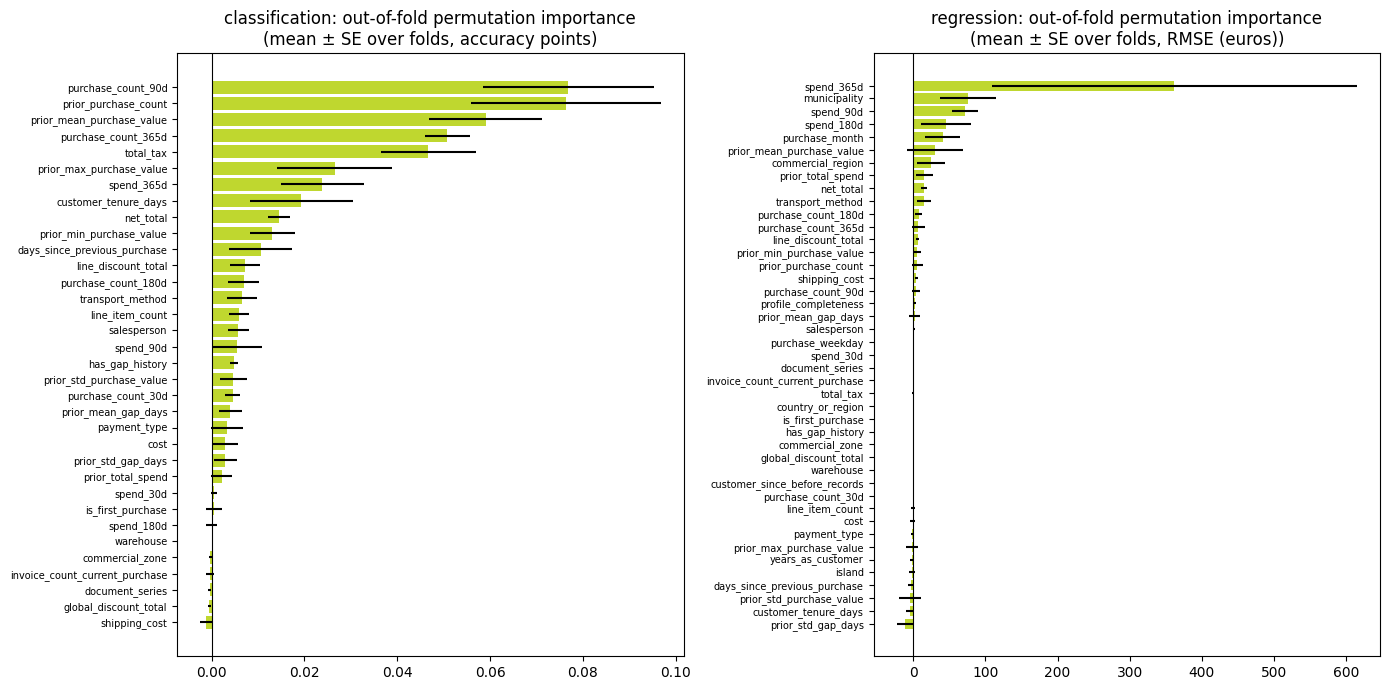

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, task in zip(axes, TASKS):
    p = perm[task].sort_values("mean")
    ax.barh(p.index, p["mean"], xerr=p["std_between_folds"] / np.sqrt(len(folds[task])), color="#BFD72F")
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"{task}: out-of-fold permutation importance\n(mean ± SE over folds, {unit[task]})")
    ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()

# <font color='#2E86C1' size=6>**6. Drop candidates**</font> <a class="anchor" id="candidates"></a>

One row per feature in the recipe, with the evidence side by side. A feature is flagged as a **drop candidate** when it satisfies **both**:

- *not useful*: mean permutation importance `<= 0`, or positive on at most 2 of the folds;
- *and* either *redundant* (it shares a Spearman cluster with another feature in the recipe) or *irrelevant* (MI not above the shuffled-target maximum).

The two-condition rule is deliberately strict: a single weak signal (for example a low importance on its own) is not enough to remove a column, because with 5 folds and a few thousand rows the importance of correlated features is split between them and each looks weaker than it is.

[Back to TOC](#toc)

In [11]:
def candidate_table(task):
    g = groups[task]
    used = [c for c in g["used"] if c in perm[task].index]
    sizes = cluster[task].map(cluster[task].value_counts())
    in_recipe_in_cluster = {
        c: [m for m in cluster[task][cluster[task] == cluster[task].get(c)].index if m != c and m in g["used"]]
        for c in used if c in cluster[task].index}
    table = pd.DataFrame(index=used)
    table["VIF"] = vif[task].reindex(used)
    table["MI"] = mi[task].reindex(used)
    table["perm_mean"] = perm[task]["mean"]
    table["perm_folds_positive"] = perm[task]["folds_positive"]
    table["redundant_with"] = pd.Series({c: ", ".join(v) for c, v in in_recipe_in_cluster.items()})
    not_useful = (table["perm_mean"] <= 0) | (table["perm_folds_positive"] <= 2)
    redundant = table["redundant_with"].fillna("") != ""
    irrelevant = table["MI"] <= mi_floor[task].max()
    table["drop_candidate"] = not_useful & (redundant | irrelevant)
    return table.sort_values(["drop_candidate", "perm_mean"], ascending=[False, True])


candidates = {task: candidate_table(task) for task in TASKS}
for task in TASKS:
    t = candidates[task]
    print(f"\n{task.upper()}: {int(t['drop_candidate'].sum())} drop candidates out of {len(t)} features in the recipe")
    display(t.round(4).head(15))


CLASSIFICATION: 8 drop candidates out of 34 features in the recipe


,VIF,MI,perm_mean,perm_folds_positive,redundant_with,drop_candidate
shipping_cost,1.1060,0.0042,-0.0012,2,,True
global_discount_total,1.0144,0.0027,-0.0005,0,,True
document_series,NaN,0.0007,-0.0004,0,NaN,True
invoice_count_current_purchase,1.1156,0.0023,-0.0003,3,,True
commercial_zone,NaN,0.0015,-0.0002,1,NaN,True
warehouse,NaN,0.0006,0.0000,0,NaN,True
spend_180d,10.6635,0.0846,0.0000,2,spend_365d,True
is_first_purchase,3.0197,0.0110,0.0005,2,,True
spend_30d,2.7632,0.0254,0.0005,3,purchase_count_30d,False
prior_total_spend,8.2992,0.0639,0.0021,3,prior_purchase_count,False



REGRESSION: 12 drop candidates out of 43 features in the recipe


,VIF,MI,perm_mean,perm_folds_positive,redundant_with,drop_candidate
prior_std_purchase_value,18.5218,0.2135,-3.8507,3,prior_max_purchase_value,True
prior_max_purchase_value,10.6964,0.2959,-1.2669,4,prior_std_purchase_value,True
cost,3.4453,0.0000,-0.9435,4,,True
line_item_count,2.1348,0.0056,-0.2026,3,,True
purchase_count_30d,4.9964,0.0847,-0.1502,2,spend_30d,True
customer_since_before_records,1.4039,0.0122,-0.0357,2,,True
warehouse,NaN,0.0066,-0.0002,2,NaN,True
global_discount_total,1.0322,0.0028,-0.0000,1,,True
commercial_zone,NaN,0.0058,0.0026,1,NaN,True
has_gap_history,3.7914,0.0182,0.0031,1,,True


### 6.1 A first engineering hint: the tax rate

`total_tax` is the 5th most important column for classification (more than `net_total`, which it is almost proportional to). A ratio of the two columns is the tax rate of the invoice; if it takes a handful of fixed values, those values behave like a categorical variable (VAT band, which depends on the product mix or the delivery region) that no current feature exposes directly.

In [12]:
X, y = data["classification"]["X_dev"], data["classification"]["y_dev"]
tax_rate = (X["total_tax"].astype("float64") / X["net_total"].astype("float64")).replace([np.inf, -np.inf], np.nan)
band = tax_rate.round(2).where(tax_rate.round(2).isin(tax_rate.round(2).value_counts().head(4).index), other=np.nan)
by_band = (pd.DataFrame({"band": band.fillna(-1), "repeat_purchase_90d": y})
           .groupby("band")["repeat_purchase_90d"].agg(["size", "mean"]).rename(columns={"size": "rows", "mean": "repurchase_rate"}))
by_band.index = by_band.index.map(lambda v: "other" if v == -1 else f"{v:.2f}")
print(f"distinct tax rates (rounded to 2 decimals): {tax_rate.round(2).nunique()}")
display(by_band.round(3))

distinct tax rates (rounded to 2 decimals): 20


,rows,repurchase_rate
band,,
other,228,0.399
0.00,127,0.386
0.13,191,0.691
0.22,105,0.667
0.23,4373,0.553


# <font color='#2E86C1' size=6>**7. What to do with this**</font> <a class="anchor" id="what-to-do"></a>

1. **Redundancy and drop candidates** feed the in-pipeline `selection` step (variance threshold, L1 / forest-based selector, top-k) that is added to `build_pipeline`; the same candidates are also tested as a manual ablation (recipe minus the candidate group).
2. **Features worth engineering** are the ones whose information is spread over several correlated columns (the 30/90/180/365-day windows and the `prior_*` statistics): ratios and differences between them (trend, overdue ratio, frequency) are the first engineering candidates.
3. Every decision, kept or rejected, goes to `config.yaml` with a comment pointing to the section of this notebook, and to sections 5 and 12 of the README.

*Caveats: (a) permutation importance depends on the model in `config.yaml`; if the group changes the final model, re-run this notebook. (b) With correlated features, the importance of a group is shared among its members, so the ablation is the arbiter, not this table.*

[Back to TOC](#toc)

# <font color='#2E86C1' size=6>**8. Step 2: engineered features, paired ablation**</font> <a class="anchor" id="engineering"></a>

Candidates (computed in `config.yaml` → `diagnostics.derived_features`, only used when listed in the recipe), all known at the moment of the purchase and built from columns of the same row:

- `tax_rate = total_tax / net_total`: VAT band of the invoice (section 6.1);
- `overdue_ratio = days_since_previous_purchase / prior_mean_gap_days`: above 1 means the customer is later than their usual rhythm (NaN, then median, for customers without gap history; `has_gap_history` is already a flag);
- `purchase_rate = prior_purchase_count / (customer_tenure_days + 1)`: purchases per day of tenure.
- `count_share_90d = purchase_count_90d / (purchase_count_365d + 1)`: how much of the year's activity is recent;
- `ticket_vs_usual = net_total / prior_mean_purchase_value`: this invoice against the customer's usual ticket (NaN for first purchases);
- `spend_trend = spend_90d - (spend_180d - spend_90d)`: spend in the last 90 days minus spend in the 90 days before (positive: accelerating);
- `gap_variability = prior_std_gap_days / prior_mean_gap_days`: irregularity of the purchase rhythm (NaN without gap history).

`tax_pct` is a **notebook-only** variant: the same tax rate rounded to whole percent and treated as a *categorical* (target-encoded) variable. A linear model cannot use `tax_rate` well if the relation is not monotonic (section 6.1: 13 % and 22 % high, 23 % medium, 0 % low); if `tax_pct` wins, it becomes a stateless step in `src/cleaning.py`.

Every variant is the task's **current recipe** plus the listed feature(s), scored on the same temporal folds. Positive `mean_advantage` means the variant is better than `current` (RMSE differences are sign-flipped); `decisive` means more than 2 standard errors from zero, the rule of notebook 01, section 7. With about ten variants per task, roughly one pass at 2 SE can happen by chance alone, so a single borderline pass is weak evidence: prefer features that help in at least 4 of 5 folds **and** in both tasks, or that have a reason to help beyond the number.

[Back to TOC](#toc)

In [13]:
NEW_FEATURES = ["tax_rate", "overdue_ratio", "purchase_rate", "count_share_90d", "ticket_vs_usual", "spend_trend", "gap_variability"]
BEHAVIOUR = [f for f in NEW_FEATURES if f != "tax_rate"]
missing = [f for task in TASKS for f in NEW_FEATURES if f not in data[task]["X_dev"].columns]
assert not missing, f"{missing} not in X_dev: add them to config.yaml -> diagnostics.derived_features"


def model_factory(task):
    return lambda: get_task(task).model.build_model(config[task]["model"])


def with_extra(recipe, numeric=(), categorical=()):
    return {**recipe, "numeric_features": recipe["numeric_features"] + list(numeric),
            "categorical_features": recipe["categorical_features"] + list(categorical)}


def run_ablation(task, X, variants, baseline="current"):
    """Scores every variant on the task's temporal folds; returns (scores, paired comparison vs baseline)."""
    metric = config[task]["selection_metric"]
    higher = greater_is_better(SCORING[task][metric])
    table, per_fold = compare_preprocessing_variants(
        variants, model_factory(task), X, data[task]["y_dev"], folds[task], SCORING[task], metric)
    paired = pd.DataFrame([{"variant": name, **paired_comparison(per_fold[name], per_fold[baseline], higher)}
                           for name in variants if name != baseline]).set_index("variant")
    return table, paired


def tax_pct(X):
    pct = (X["total_tax"].astype("float64") / X["net_total"].astype("float64") * 100).replace([np.inf, -np.inf], np.nan).round()
    return pct.map(lambda v: f"{int(v)}" if pd.notna(v) else np.nan)


engineering = {}
for task in TASKS:
    X = data[task]["X_dev"].assign(tax_pct=lambda d: tax_pct(d))
    recipe = data[task]["preprocessing_config"]
    variants = {"current": recipe}
    for feature in NEW_FEATURES:
        variants[f"+ {feature}"] = with_extra(recipe, [feature])
    variants["+ tax_pct (categorical)"] = with_extra(recipe, categorical=["tax_pct"])
    variants["+ all behaviour features"] = with_extra(recipe, BEHAVIOUR)
    variants["+ all numeric"] = with_extra(recipe, NEW_FEATURES)
    engineering[task] = run_ablation(task, X, variants)
    metric = config[task]["selection_metric"]
    print(f"\n{task.upper()} ({metric}, {'higher' if greater_is_better(SCORING[task][metric]) else 'lower'} is better)")
    display(engineering[task][0].round(4))
    display(engineering[task][1].round(4))


CLASSIFICATION (accuracy, higher is better)


,variant,mean_accuracy,std_accuracy
0,+ tax_pct (categorical),0.7090,0.0147
1,current,0.7078,0.0155
2,+ ticket_vs_usual,0.7078,0.0173
3,+ tax_rate,0.7076,0.0176
4,+ spend_trend,0.7074,0.0164
5,+ gap_variability,0.7057,0.0162
6,+ overdue_ratio,0.7054,0.0157
7,+ all behaviour features,0.7040,0.0117
8,+ purchase_rate,0.7040,0.0155
9,+ count_share_90d,0.7033,0.0140


,mean_advantage,se,folds_a_better,n_folds,decisive
variant,,,,,
+ tax_rate,-0.0002,0.0012,3,5,False
+ overdue_ratio,-0.0024,0.0016,1,5,False
+ purchase_rate,-0.0038,0.0007,0,5,True
+ count_share_90d,-0.0045,0.0017,0,5,True
+ ticket_vs_usual,-0.0000,0.0016,2,5,False
+ spend_trend,-0.0005,0.0005,0,5,False
+ gap_variability,-0.0021,0.0006,0,5,True
+ tax_pct (categorical),0.0012,0.0016,3,5,False
+ all behaviour features,-0.0038,0.0027,1,5,False



REGRESSION (rmse, lower is better)


,variant,mean_rmse,std_rmse
0,+ purchase_rate,1937.8644,169.1976
1,+ overdue_ratio,1941.9034,163.4446
2,+ ticket_vs_usual,1942.0403,166.0439
3,+ tax_rate,1942.4780,166.8666
4,current,1942.4794,165.1851
5,+ tax_pct (categorical),1943.1322,164.1238
6,+ spend_trend,1944.2807,167.5219
7,+ count_share_90d,1949.1372,172.6647
8,+ gap_variability,1965.2095,199.5865
9,+ all behaviour features,1967.8679,205.5330


,mean_advantage,se,folds_a_better,n_folds,decisive
variant,,,,,
+ tax_rate,0.0015,1.3941,2,5,False
+ overdue_ratio,0.5760,1.1629,2,5,False
+ purchase_rate,4.6150,2.5591,4,5,False
+ count_share_90d,-6.6578,10.1485,3,5,False
+ ticket_vs_usual,0.4391,0.6939,4,5,False
+ spend_trend,-1.8013,6.3652,3,5,False
+ gap_variability,-22.7301,28.0366,2,5,False
+ tax_pct (categorical),-0.6528,2.1391,1,5,False
+ all behaviour features,-25.3884,32.5297,3,5,False


# <font color='#2E86C1' size=6>**9. Step 3: feature selection, paired ablation**</font> <a class="anchor" id="selection"></a>

Every selector below sits **inside the Pipeline**, between the recipe and the model (`preprocessing.selection` in `config.yaml`, built by `build_selector` in `src/preprocessing.py`), so it is fitted on the training rows of each fold and never sees the validation rows. All variants start from the task's current recipe, so the comparison isolates the effect of selecting.

- `manual: drop candidates` removes the drop candidates of section 6 from the recipe (they were chosen on all development rows, so this variant is slightly optimistic: it is a reference, not a clean estimate). An imputation setting that reads a removed column goes with it: without `spend_180d`, `spend_365d` keeps its upper row limit but loses its lower one;
- `variance` drops constant columns; `kbest` keeps the k columns with the highest mutual information; `forest` keeps columns whose forest importance is above the mean (or median); `l1` keeps the columns with a non-zero L1 coefficient (logistic regression with strength `C`, Lasso with `alpha`).

Decision rule: add a selector only if it is decisively better, or not decisively worse **and** keeps clearly fewer columns (parsimony). Report either outcome.

[Back to TOC](#toc)

In [14]:
def drop_features(recipe, names):
    """The recipe without `names`. An imputation setting that reads a dropped column goes with it:
    a row limit, a fit-row rule or a column estimate can't use a column the recipe no longer has."""
    names = set(names)
    reads_dropped = lambda setting: any(re.search(rf"\b{name}\b", str(setting)) for name in names)
    imputation = recipe.get("imputation", {})
    row_bounds = {column: {side: limit for side, limit in limits.items() if not reads_dropped(limit)}
                  for column, limits in imputation.get("row_bounds", {}).items() if column not in names}
    kept = lambda setting: {column: spec for column, spec in imputation.get(setting, {}).items()
                            if column not in names and not reads_dropped(spec)}
    return {**recipe, **{key: [c for c in recipe.get(key, []) if c not in names]
                         for key in ["numeric_features", "categorical_features", "flag_features", "mnar_indicator_sources"]},
            "imputation": {**imputation, "row_bounds": {c: limits for c, limits in row_bounds.items() if limits},
                           "fit_rows": kept("fit_rows"), "column_imputers": kept("column_imputers")}}


L1_GRID = {"classification": [{"C": 0.01}, {"C": 0.1}, {"C": 1.0}],
           "regression": [{"alpha": 1.0}, {"alpha": 10.0}, {"alpha": 100.0}]}


def selection_variants(task):
    recipe = data[task]["preprocessing_config"]
    manual = candidates[task].index[candidates[task]["drop_candidate"]]
    chosen = lambda **sel: {**recipe, "selection": sel}
    variants = {"current": recipe, "manual: drop candidates": drop_features(recipe, manual),
                "variance": chosen(method="variance"),
                "kbest k=20": chosen(method="kbest", k=20), "kbest k=15": chosen(method="kbest", k=15),
                "forest mean": chosen(method="forest", threshold="mean"),
                "forest median": chosen(method="forest", threshold="median")}
    for params in L1_GRID[task]:
        variants["l1 " + ", ".join(f"{k}={v}" for k, v in params.items())] = chosen(method="l1", **params)
    return variants


def kept_summary(task, variants):
    X, y = data[task]["X_dev"], data[task]["y_dev"]
    rows = []
    for name, recipe in variants.items():
        pipeline = build_pipeline(recipe, model_factory(task)()).fit(X, y)
        width = pipeline.named_steps["prep"].transform(X.iloc[:5]).shape[1]
        kept = list(pipeline[:-1].get_feature_names_out())
        every = list(pipeline.named_steps["prep"].get_feature_names_out())
        rows.append({"variant": name, "columns kept": len(kept), "of": width,
                     "dropped": ", ".join(c.split("__", 1)[-1] for c in every if c not in kept)})
    return pd.DataFrame(rows).set_index("variant")


selection = {}
for task in TASKS:
    variants = selection_variants(task)
    selection[task] = run_ablation(task, data[task]["X_dev"], variants) + (kept_summary(task, variants),)
    metric = config[task]["selection_metric"]
    print(f"\n{task.upper()} ({metric}, {'higher' if greater_is_better(SCORING[task][metric]) else 'lower'} is better)")
    display(selection[task][0].round(4))
    display(selection[task][1].round(4))
    with pd.option_context("display.max_colwidth", 140):
        display(selection[task][2])


CLASSIFICATION (accuracy, higher is better)


,variant,mean_accuracy,std_accuracy
0,manual: drop candidates,0.7105,0.0167
1,l1 C=1.0,0.7100,0.0194
2,forest median,0.7100,0.0142
3,l1 C=0.1,0.7100,0.0209
4,kbest k=20,0.7081,0.0209
5,current,0.7078,0.0155
6,variance,0.7078,0.0155
7,forest mean,0.7071,0.0155
8,kbest k=15,0.7054,0.0191
9,l1 C=0.01,0.6992,0.0150


,mean_advantage,se,folds_a_better,n_folds,decisive
variant,,,,,
manual: drop candidates,0.0026,0.0029,2,5,False
variance,0.0000,0.0000,0,5,False
kbest k=20,0.0002,0.0053,3,5,False
kbest k=15,-0.0024,0.0056,1,5,False
forest mean,-0.0007,0.0048,2,5,False
forest median,0.0021,0.0039,3,5,False
l1 C=0.01,-0.0086,0.0076,1,5,False
l1 C=0.1,0.0021,0.0037,3,5,False
l1 C=1.0,0.0021,0.0031,2,5,False


,columns kept,of,dropped
variant,,,
current,35,35,
manual: drop candidates,27,27,
variance,35,35,
kbest k=20,20,35,"net_total, total_tax, shipping_cost, global_discount_total, line_discount_total, cost, line_item_count, invoice_count_current_purchase, ..."
kbest k=15,15,35,"net_total, total_tax, shipping_cost, global_discount_total, line_discount_total, cost, line_item_count, invoice_count_current_purchase, ..."
forest mean,20,35,"shipping_cost, global_discount_total, line_item_count, invoice_count_current_purchase, prior_min_purchase_value, purchase_count_30d, spe..."
forest median,18,35,"shipping_cost, global_discount_total, line_item_count, invoice_count_current_purchase, customer_tenure_days, prior_purchase_count, prior..."
l1 C=0.01,7,35,"net_total, total_tax, shipping_cost, global_discount_total, line_discount_total, cost, line_item_count, invoice_count_current_purchase, ..."
l1 C=0.1,19,35,"cost, invoice_count_current_purchase, days_since_previous_purchase, prior_total_spend, prior_mean_purchase_value, prior_std_purchase_val..."



REGRESSION (rmse, lower is better)


,variant,mean_rmse,std_rmse
0,l1 alpha=1.0,1932.9648,156.9241
1,manual: drop candidates,1933.6376,142.9053
2,variance,1942.4794,165.1851
3,current,1942.4794,165.1851
4,forest median,1946.4382,167.7057
5,forest mean,1955.1652,162.7838
6,l1 alpha=10.0,1959.2417,179.4233
7,kbest k=15,2002.0249,195.1420
8,kbest k=20,2010.5817,200.2362
9,l1 alpha=100.0,2145.6679,196.9061


,mean_advantage,se,folds_a_better,n_folds,decisive
variant,,,,,
manual: drop candidates,8.8419,11.2965,4,5,False
variance,0.0000,0.0000,1,5,False
kbest k=20,-68.1022,27.7894,0,5,True
kbest k=15,-59.5455,29.8316,1,5,False
forest mean,-12.6858,3.8041,0,5,True
forest median,-3.9588,3.4344,2,5,False
l1 alpha=1.0,9.5146,8.9434,2,5,False
l1 alpha=10.0,-16.7623,28.2088,2,5,False
l1 alpha=100.0,-203.1884,52.5168,0,5,True


,columns kept,of,dropped
variant,,,
current,44,44,
manual: drop candidates,32,32,
variance,44,44,
kbest k=20,20,44,"net_total, total_tax, shipping_cost, global_discount_total, line_discount_total, cost, line_item_count, invoice_count_current_purchase, ..."
kbest k=15,15,44,"net_total, total_tax, shipping_cost, global_discount_total, line_discount_total, cost, line_item_count, invoice_count_current_purchase, ..."
forest mean,8,44,"net_total, total_tax, shipping_cost, global_discount_total, line_discount_total, cost, line_item_count, invoice_count_current_purchase, ..."
forest median,22,44,"total_tax, shipping_cost, global_discount_total, invoice_count_current_purchase, days_since_previous_purchase, purchase_count_30d, spend..."
l1 alpha=1.0,36,44,"net_total, total_tax, global_discount_total, prior_min_purchase_value, prior_max_purchase_value, prior_std_gap_days, purchase_count_90d,..."
l1 alpha=10.0,22,44,"net_total, total_tax, shipping_cost, global_discount_total, line_discount_total, cost, line_item_count, invoice_count_current_purchase, ..."


# <font color='#2E86C1' size=6>**10. Decisions**</font> <a class="anchor" id="decisions"></a>

**Scope.** All numbers come from sections 6, 8 and 9 of this notebook (five temporal folds, development set only; classification scored with logistic regression and accuracy, regression with a random forest and RMSE). The final report will use probably other models, so the decisions below are about columns, not models, and rest as far as possible on evidence that does not depend on a single model: mutual information against a shuffled-target noise floor, exact duplicates and correlation. Permutation importance is only supporting evidence: near zero it is noisy, and the number of regression drop candidates went from 11 to 9 between two runs after columns were added to the data, and it is 12 in the current run.

**Features to create.** Of the seven engineered features, only `purchase_rate` (`prior_purchase_count / (customer_tenure_days + 1)`) helps, and only in regression: RMSE improves by 4.6 (about 0.2 %), in 4 of 5 folds, at 1.8 standard errors, so not decisively. With about ten comparisons per task this is weak evidence, so it is kept as an optional feature with a small expected gain, not as a finding. In classification it is decisively worse (−0.0038 accuracy, worse on all 5 folds), and so are `count_share_90d` (−0.0045) and `gap_variability` (−0.0021). Its mutual information with the target is among the highest in both tasks (4th in classification, 3rd in regression), but logistic regression, which cannot form ratios by itself, still gets worse with it. `tax_rate`, `tax_pct`, `overdue_ratio`, `ticket_vs_usual` and `spend_trend` change nothing (no difference is decisive), and `gap_variability` makes regression worse and less stable (RMSE +23, standard deviation across folds from 165 to 200). None of them is created.

**Columns to delete.** Columns without signal (mutual information below the noise floor, zero or negligible permutation importance): in both tasks `global_discount_total`, `commercial_zone` and `warehouse`; in classification also `document_series`, `shipping_cost`, `invoice_count_current_purchase` and `is_first_purchase` (identical to `prior_purchase_count == 0`); in regression also `cost`, `line_item_count`, `country_or_region`, `customer_since_before_records`, `has_gap_history` (identical to `prior_purchase_count >= 2`) and `profile_completeness`. In regression, `document_series` and `purchase_weekday` are below the noise floor too, but they now help slightly (under 1 RMSE, on 3–4 of 5 folds), so they stay until the confirming ablation. Removing the drop candidates of section 6 by hand did not hurt: accuracy +0.0026 (better on 2 of 5 folds) with 27 instead of 35 model columns, RMSE 8.8 lower (not decisive, better on 4 of 5 folds) with 32 instead of 44. Both numbers are optimistic, because the candidates were chosen on the same rows, and the final lists above differ slightly from the tested ones, so they still need one confirming ablation.

**Redundant but informative.** `spend_180d` (classification), `purchase_count_30d` and the pair `prior_std_purchase_value` / `prior_max_purchase_value` (regression: each is a drop candidate because of the other, so at most one of them can go) and `purchase_count_180d` (VIF 29) duplicate information held by other columns. Tree-based models tolerate this, so they are removed only if a linear or distance-based model is among the final five.

**Feature-selection step.** No automatic selector is decisively better than the full recipe, and none clearly beats the manual list. In regression, `kbest` (k = 20), forest-mean selection and L1 with `alpha=100` are decisively worse; L1 with `alpha=1` is 9.5 RMSE better (not decisive) with 36 of 44 columns, level with the manual list. In classification, L1 logistic regression (`C=0.1`) and forest-median selection match the full recipe (+0.002) with 19 and 18 of 35 columns, but that result depends on the model. The `selection` step stays in the pipeline with `method: none` as the default and can be re-tested once the five models are fixed.

**Limits.** The evidence comes from logistic regression and a random forest only. Sections 8 and 9 should be re-run for each of the final models before the lists are frozen.

[Back to TOC](#toc)

# <font color='#2E86C1' size=6>**11. From this notebook to the pipeline**</font> <a class="anchor" id="to-pipeline"></a>

| This notebook | Pipeline |
|---|---|
| Section 1 | `src/evaluate.py` → `compare_preprocessing_variants()`; `src/preprocessing.py` → `RareCategoryGrouper`; `config.yaml` → `<task>.preprocessing.extra_*_features`, `preprocessing.rare_category_min_count` |
| Sections 8–9 | `config.yaml` → `diagnostics.derived_features` (engineered features), `preprocessing.selection`; `src/preprocessing.py` → `build_selector()` |

[Back to TOC](#toc)